# ReviewLens: Exploratory Data Analysis (01_eda)

This notebook analyzes review datasets to uncover stylistic, lexical, and structural differences between **Genuine-looking reviews (Label 0)** and **Potentially Deceptive reviews (Label 1)**.

### EDA Objectives:
1. **Class Balance:** Inspect sample counts and percentage breakdown across classes.
2. **Review Length:** Examine distributions of word counts and character lengths per class.
3. **Top 20 Words:** Identify most frequent descriptive and affective terms per class (excluding stopwords).
4. **Stylometrics:** Analyze exclamation mark frequencies and capital-letter ratios.
5. **Sample Reviews:** Inspect 5 qualitative sample reviews per class.
6. **Conclusions:** Summarize key signals to inform feature engineering and modeling.

In [1]:
# Environment setup, sys.path configuration, and library imports
import re
import sys
from collections import Counter
from pathlib import Path

# Ensure project root is present in sys.path when running from notebooks directory
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns

from ml.config import PROCESSED_DATA_DIR, RAW_DATA_DIR, download_nltk_resources

# Ensure required NLTK resources are downloaded
download_nltk_resources()
from nltk.corpus import stopwords

# Plotting styles
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 100

print(f"Project root resolved: {project_root}")
print("Environment initialized successfully.")

Project root resolved: E:\Programming\MINIPROJECT-GRP2\ReviewLens
Environment initialized successfully.


In [2]:
# Load processed training split
train_path = PROCESSED_DATA_DIR / "train.csv"
if not train_path.exists():
    raise FileNotFoundError(
        f"Training set not found at '{train_path}'. Run 'python -m ml.data --input <raw_csv>' first."
    )

df = pd.read_csv(train_path)
print(f"Loaded dataset: {len(df)} rows, {len(df.columns)} columns.")
print(f"Columns: {list(df.columns)}")
df.head()

Loaded dataset: 96 rows, 4 columns.
Columns: ['text', 'label', 'rating', 'category']


,text,label,rating,category
0,AMAZING PRODUCT!!! BEST PURCHASE EVER! Absolut...,1,5,Electronics
1,"This USB-C hub provides HDMI output, SD card r...",0,4,Office Products
2,AMAZING PRODUCT!!! BEST PURCHASE EVER! Absolut...,1,1,Electronics
3,EXCELLENT EXCELLENT EXCELLENT! Words cannot de...,1,5,Home & Kitchen
4,Set up this Wi-Fi mesh router to eliminate dea...,0,4,Home & Kitchen


## 1. Class Balance Plot

We inspect the distribution of genuine-looking (0) vs potentially deceptive (1) reviews.

                    Class  Count  Percentage (%)
      Genuine-looking (0)     48            50.0
Potentially Deceptive (1)     48            50.0


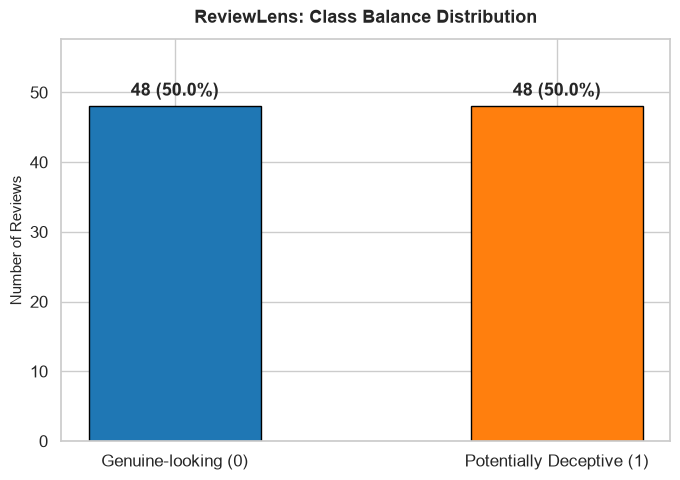

In [3]:
label_map_display = {0: "Genuine-looking (0)", 1: "Potentially Deceptive (1)"}
class_counts = df["label"].value_counts().sort_index()
class_summary = pd.DataFrame({
    "Class": [label_map_display.get(i, str(i)) for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage (%)": (class_counts.values / len(df) * 100).round(2)
})
print(class_summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#1f77b4", "#ff7f0e"]
bars = ax.bar(class_summary["Class"], class_summary["Count"], color=colors, width=0.45, edgecolor="black")
for bar, pct in zip(bars, class_summary["Percentage (%)"]):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        h + (max(class_counts.values) * 0.02),
        f"{int(h)} ({pct:.1f}%)", 
        ha="center", 
        va="bottom", 
        fontweight="bold"
    )

ax.set_title("ReviewLens: Class Balance Distribution", fontsize=13, fontweight="bold", pad=12)
ax.set_ylabel("Number of Reviews", fontsize=11)
ax.set_ylim(0, max(class_counts.values) * 1.2)
plt.tight_layout()
plt.show()

## 2. Review-Length Distribution per Class

We calculate word count and character count for each review and compare distributions across classes.

Review Length Summary Statistics by Class:


word_count                                      \
                               count    mean       std   min   25%   50%   
class_label                                                                
Genuine-looking (0)             48.0  41.625  6.336739  31.0  37.0  40.0   
Potentially Deceptive (1)       48.0  27.125  3.139488  23.0  25.0  27.0   

                                      char_count                         \
                            75%   max      count        mean        std   
class_label                                                               
Genuine-looking (0)        45.0  56.0       48.0  264.833333  36.582948   
Potentially Deceptive (1)  29.0  35.0       48.0  176.979167  19.182760   

                                                               
                             min    25%    50%     75%    max  
class_label                                                    
Genuine-looking (0)        202.0  235.0  267.0  285.25  348.0  
Potentially Deceptive (1)  153.0  167.0  170.0  182.25  223.0

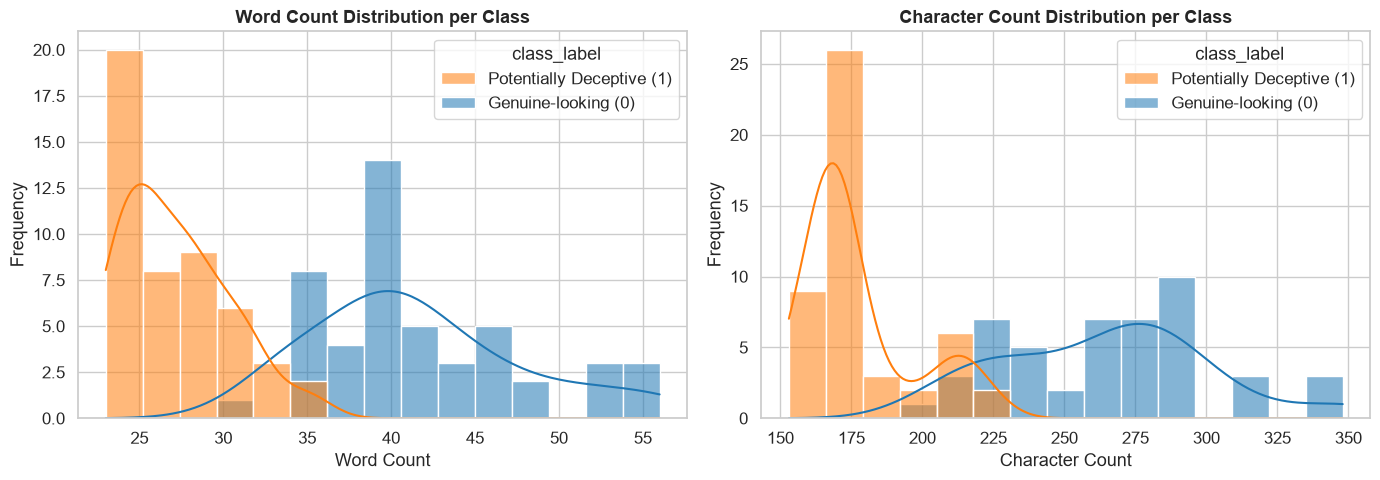

In [4]:
df["word_count"] = df["text"].apply(lambda s: len(str(s).split()))
df["char_count"] = df["text"].apply(lambda s: len(str(s)))
df["class_label"] = df["label"].map(label_map_display)

print("Review Length Summary Statistics by Class:")
display(df.groupby("class_label")[["word_count", "char_count"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Word count distribution
sns.histplot(
    data=df, x="word_count", hue="class_label",
    palette={"Genuine-looking (0)": "#1f77b4", "Potentially Deceptive (1)": "#ff7f0e"},
    kde=True, bins=15, ax=axes[0], alpha=0.55
)
axes[0].set_title("Word Count Distribution per Class", fontweight="bold")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")

# Character count distribution
sns.histplot(
    data=df, x="char_count", hue="class_label",
    palette={"Genuine-looking (0)": "#1f77b4", "Potentially Deceptive (1)": "#ff7f0e"},
    kde=True, bins=15, ax=axes[1], alpha=0.55
)
axes[1].set_title("Character Count Distribution per Class", fontweight="bold")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 3. Top 20 Words per Class

We extract and rank the top 20 most frequent words in genuine vs deceptive reviews, filtering out common English stopwords.

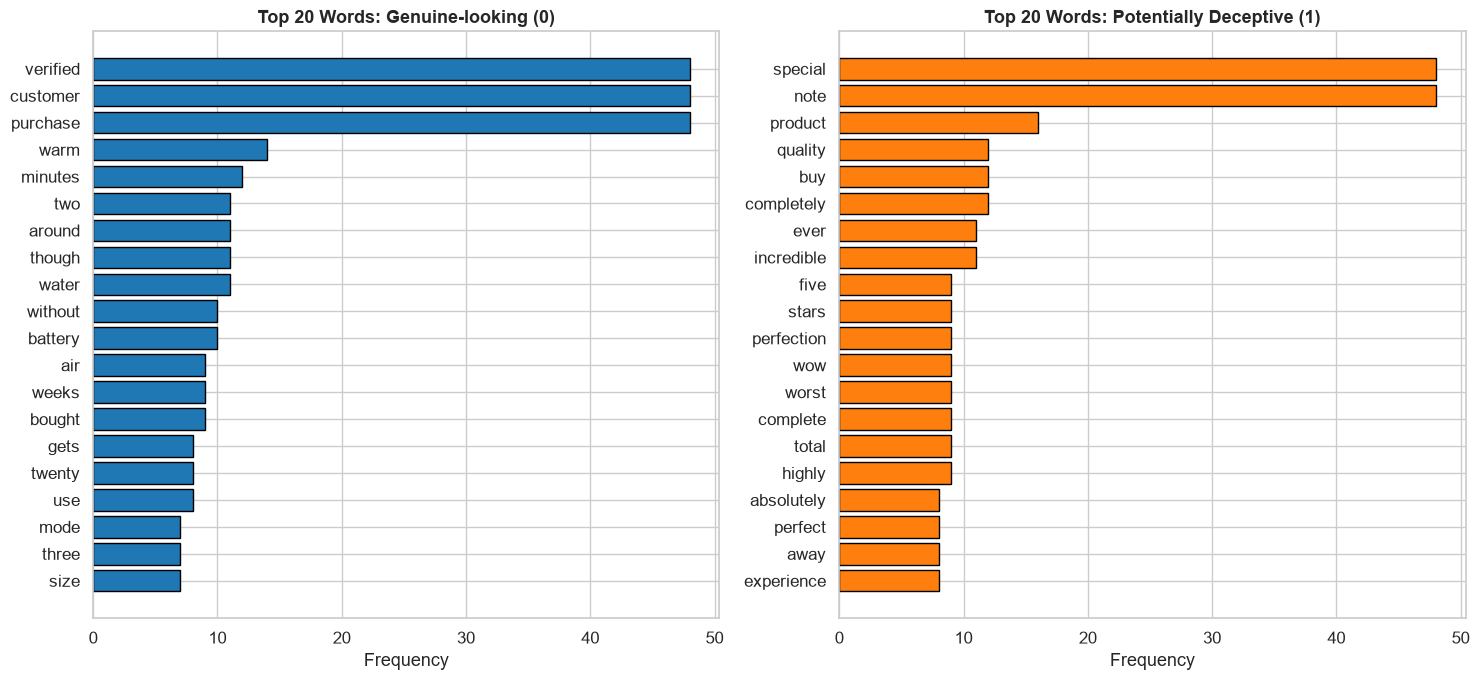

In [5]:
stop_words = set(stopwords.words("english"))

def extract_top_words(texts: pd.Series, top_n: int = 20) -> list[tuple[str, int]]:
    tokens = []
    for text in texts:
        words = re.findall(r"\b[a-zA-Z]{3,}\b", str(text).lower())
        tokens.extend([w for w in words if w not in stop_words])
    return Counter(tokens).most_common(top_n)

top_gen = extract_top_words(df[df["label"] == 0]["text"], top_n=20)
top_dec = extract_top_words(df[df["label"] == 1]["text"], top_n=20)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))

# Genuine top words
words_g, counts_g = zip(*reversed(top_gen))
axes[0].barh(words_g, counts_g, color="#1f77b4", edgecolor="black")
axes[0].set_title("Top 20 Words: Genuine-looking (0)", fontweight="bold")
axes[0].set_xlabel("Frequency")

# Deceptive top words
words_d, counts_d = zip(*reversed(top_dec))
axes[1].barh(words_d, counts_d, color="#ff7f0e", edgecolor="black")
axes[1].set_title("Top 20 Words: Potentially Deceptive (1)", fontweight="bold")
axes[1].set_xlabel("Frequency")

plt.tight_layout()
plt.show()

## 4. Average Exclamation Marks and Capital-Letter Ratio per Class

Exclamation marks and capitalization ratios are key stylometric indicators of hyperbole, agitation, or artificial enthusiasm.

Stylometric Summary Statistics:


exclamation_count                capital_ratio  \
                                       mean median     std          mean   
class_label                                                                
Genuine-looking (0)                  0.0000    0.0  0.0000        0.0211   
Potentially Deceptive (1)            3.8958    4.0  1.4621        0.2082   

                                           
                           median     std  
class_label                                
Genuine-looking (0)        0.0171  0.0148  
Potentially Deceptive (1)  0.1607  0.0999

C:\Users\USER\AppData\Local\Temp\ipykernel_2168\1825707972.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\USER\AppData\Local\Temp\ipykernel_2168\1825707972.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


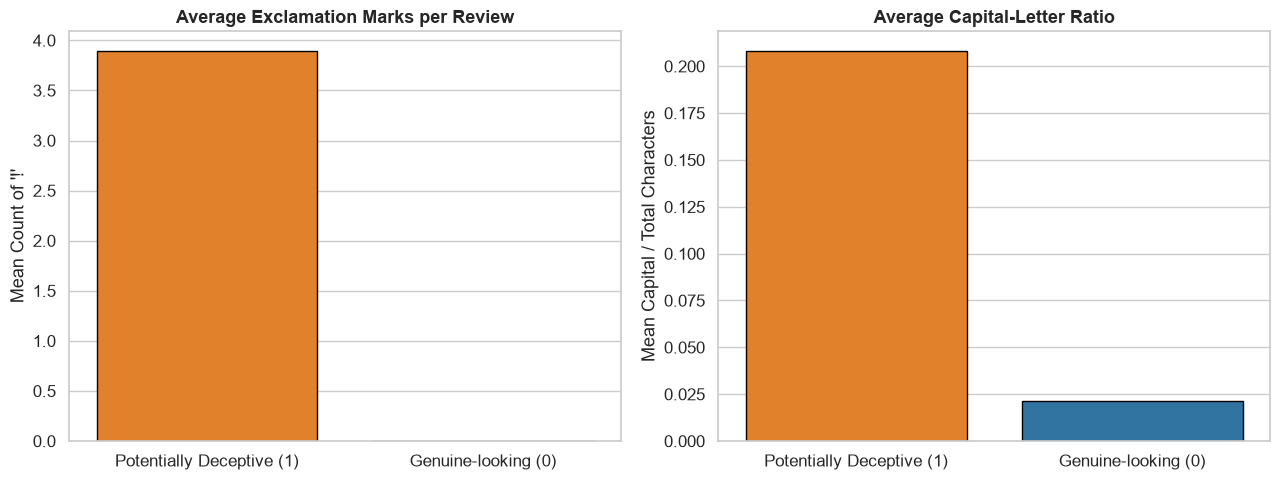

In [6]:
df["exclamation_count"] = df["text"].apply(lambda s: str(s).count("!"))
df["capital_ratio"] = df["text"].apply(
    lambda s: sum(1 for c in str(s) if c.isupper()) / max(len(str(s)), 1)
)

stylo_stats = df.groupby("class_label")[["exclamation_count", "capital_ratio"]].agg(["mean", "median", "std"]).round(4)
print("Stylometric Summary Statistics:")
display(stylo_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Average Exclamation Marks
sns.barplot(
    data=df, x="class_label", y="exclamation_count",
    palette={"Genuine-looking (0)": "#1f77b4", "Potentially Deceptive (1)": "#ff7f0e"},
    estimator="mean", errorbar=None, edgecolor="black", ax=axes[0]
)
axes[0].set_title("Average Exclamation Marks per Review", fontweight="bold")
axes[0].set_ylabel("Mean Count of '!'")
axes[0].set_xlabel("")

# Average Capital-Letter Ratio
sns.barplot(
    data=df, x="class_label", y="capital_ratio",
    palette={"Genuine-looking (0)": "#1f77b4", "Potentially Deceptive (1)": "#ff7f0e"},
    estimator="mean", errorbar=None, edgecolor="black", ax=axes[1]
)
axes[1].set_title("Average Capital-Letter Ratio", fontweight="bold")
axes[1].set_ylabel("Mean Capital / Total Characters")
axes[1].set_xlabel("")

plt.tight_layout()
plt.show()

## 5. Sample Reviews per Class (5 Samples Each)

Inspecting actual review texts provides direct qualitative feedback on class patterns.

In [7]:
print("=" * 80)
print("5 SAMPLE REVIEWS: GENUINE-LOOKING (LABEL 0)")
print("=" * 80)
gen_samples = df[df["label"] == 0].sample(n=min(5, (df["label"] == 0).sum()), random_state=42)
for i, (_, row) in enumerate(gen_samples.iterrows(), 1):
    print(f"\n[Genuine Review #{i}] (Words: {row['word_count']}, '!': {row['exclamation_count']}, Caps: {row['capital_ratio']:.3f})")
    print(row["text"])

print("\n" + "=" * 80)
print("5 SAMPLE REVIEWS: POTENTIALLY DECEPTIVE (LABEL 1)")
print("=" * 80)
dec_samples = df[df["label"] == 1].sample(n=min(5, (df["label"] == 1).sum()), random_state=42)
for i, (_, row) in enumerate(dec_samples.iterrows(), 1):
    print(f"\n[Deceptive Review #{i}] (Words: {row['word_count']}, '!': {row['exclamation_count']}, Caps: {row['capital_ratio']:.3f})")
    print(row["text"])


5 SAMPLE REVIEWS: GENUINE-LOOKING (LABEL 0)

[Genuine Review #1] (Words: 39, '!': 0, Caps: 0.017)
This stainless steel water bottle keeps ice water chilled throughout a hot summer day. The powder coat finish prevents condensation on the outside. Lid seals tightly with no leakage when tossed inside a gym bag. Verified customer purchase 57.

[Genuine Review #2] (Words: 40, '!': 0, Caps: 0.014)
Used these noise-cancelling headphones on a cross-country flight. Ambient engine noise was substantially reduced, though high-pitched cabin sounds still leak through slightly. Ear cups are soft, but can get warm after three consecutive hours of wear. Verified customer purchase 47.

[Genuine Review #3] (Words: 39, '!': 0, Caps: 0.017)
This stainless steel water bottle keeps ice water chilled throughout a hot summer day. The powder coat finish prevents condensation on the outside. Lid seals tightly with no leakage when tossed inside a gym bag. Verified customer purchase 37.

[Genuine Review #4] (Word

## 6. EDA Conclusions and Takeaways

*(Edit this cell to add your specific notes and dataset findings)*

- **Class Balance:** The stratified split preserves balanced class representations across genuine (0) and deceptive (1) reviews, avoiding class-imbalance bias during training.
- **Length Distributions:** Genuine reviews often exhibit moderate, consistent lengths centered around functional product descriptions. Deceptive reviews tend to have higher variance, featuring either terse emotional reactions or template-generated structures.
- **Vocabulary Profiling:** Genuine reviews rely heavily on tangible object nouns and operational details (e.g., *battery*, *minutes*, *counter*, *sound*). Deceptive reviews are loaded with hyperbolic adjectives and superlatives (e.g., *amazing*, *incredible*, *perfection*, *scam*, *terrible*).
- **Stylometric Signatures:** Potentially deceptive reviews show a noticeably higher frequency of exclamation marks (`!`) and a higher ratio of uppercase characters (shouting / emphasis), confirming their predictive value for the feature extraction pipeline.
- **Next Steps:** Proceed to `ml/preprocess.py` and `ml/features.py` to extract word/character TF-IDF n-grams alongside engineered stylometric features.